In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

In [22]:
df = pd.read_csv('financial_regression.csv')
df.head()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
0,2010-01-14,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,...,45.02,43.86,44.84,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0
1,2010-01-15,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,...,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0
2,2010-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-19,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,...,47.08,45.70,46.94,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0
4,2010-01-20,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,...,47.31,45.17,47.05,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0


In [23]:
# Step 1: Ensure sorted dates
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Step 2: Drop non-trading days where gold wasn't traded
df_clean = df.dropna(subset=['gold close']).reset_index(drop=True)

# Step 3: Calculate lags and returns across consecutive valid gold-trading observations
df_clean['Close_Lag1'] = df_clean['gold close'].shift(1)
df_clean['Open_Lag1'] = df_clean['gold open'].shift(1)
df_clean['Daily_Return'] = (df_clean['gold close'] - df_clean['gold open']) / df_clean['gold open']

# Step 4: Create stationary forward target
df_clean['Target_Log_Return'] = np.log(df_clean['gold close'].shift(-1) / df_clean['gold close'])

In [24]:
# Predict the next available trading day's gold closing price.
df_clean["Target_Next_Close"] = df_clean["gold close"].shift(-1)

# Extract calendar components
df_clean["DayOfWeek"] = df_clean["date"].dt.dayofweek  # 0 = Monday, 4 = Friday
df_clean["Month"] = df_clean["date"].dt.month
df_clean["Quarter"] = df_clean["date"].dt.quarter
df_clean["DayOfYear"] = df_clean["date"].dt.dayofyear
df_clean["IsMonthEnd"] = df_clean["date"].dt.is_month_end.astype(int)


df_clean[["date","gold open","gold close","Target_Next_Close","Close_Lag1","Open_Lag1","Daily_Return","Target_Log_Return"]]

,date,gold open,gold close,Target_Next_Close,Close_Lag1,Open_Lag1,Daily_Return,Target_Log_Return
0,2010-01-14,111.51,112.03,110.86,NaN,NaN,0.004663,-0.010499
1,2010-01-15,111.35,110.86,111.52,112.03,111.51,-0.004401,0.005936
2,2010-01-19,110.95,111.52,108.94,110.86,111.35,0.005137,-0.023407
3,2010-01-20,109.97,108.94,107.37,111.52,110.95,-0.009366,-0.014516
4,2010-01-21,108.48,107.37,107.17,108.94,109.97,-0.010232,-0.001864
...,...,...,...,...,...,...,...,...
3714,2024-10-17,247.75,248.63,251.27,247.15,247.62,0.003552,0.010562
3715,2024-10-18,250.00,251.27,251.22,248.63,247.75,0.005080,-0.000199
3716,2024-10-21,252.74,251.22,253.93,251.27,250.00,-0.006014,0.010730
3717,2024-10-22,253.06,253.93,250.87,251.22,252.74,0.003438,-0.012124


In [25]:
df_clean = df_clean.dropna(
    subset=['Close_Lag1', 'Open_Lag1', 'Target_Next_Close']
).reset_index(drop=True)

In [26]:
df_clean['Month_sin'] = np.sin(
    2 * np.pi * df_clean['Month'] / 12
)

df_clean['Month_cos'] = np.cos(
    2 * np.pi * df_clean['Month'] / 12
)

df_clean['DayOfYear_sin'] = np.sin(
    2 * np.pi * df_clean['DayOfYear'] / 365.25
)

df_clean['DayOfYear_cos'] = np.cos(
    2 * np.pi * df_clean['DayOfYear'] / 365.25
)

In [ ]:
# df_clean['Oil_Return'] = df_clean['oil close'].pct_change()
# df_clean['SP500_Return'] = df_clean['sp500 close'].pct_change()
# df_clean['NASDAQ_Return'] = df_clean['nasdaq close'].pct_change()
# df_clean['Platinum_Return'] = df_clean['platinum close'].pct_change()
# df_clean['Palladium_Return'] = df_clean['palladium close'].pct_change()

In [27]:
# 1. Feature Engineering: Compute 1-day log returns for all market assets
market_price_cols = [
    'gold close', 'silver close', 'oil close', 
    'sp500 close', 'nasdaq close', 'platinum close', 'palladium close'
]

for col in market_price_cols:
    # Log return relative to previous trading day
    df_clean[f'{col}_log_ret'] = np.log(df_clean[col] / df_clean[col].shift(1))

# Volume change feature (Log difference or % change)
df_clean['gold_volume_change'] = np.log((df_clean['gold volume'] + 1) / (df_clean['gold volume'].shift(1) + 1))

In [28]:
numeric_features = [
    # Gold returns & momentum (stationary)
    'Daily_Return',          # Today's intra-day return (Close - Open) / Open
    'gold close_log_ret',    # Today's log return relative to yesterday
    'gold_volume_change',    # Daily volume percentage/log change

    # Other market log returns (stationary)
    'silver close_log_ret',
    'oil close_log_ret',
    'sp500 close_log_ret',
    'nasdaq close_log_ret',
    'platinum close_log_ret',
    'palladium close_log_ret',

    # Cyclical calendar features
    'Month_sin',
    'Month_cos',
    'DayOfYear_sin',
    'DayOfYear_cos'
]

categorical_features = [
    'DayOfWeek',
    'IsMonthEnd'
]

features = numeric_features + categorical_features

target = 'Target_Log_Return'

In [29]:
df_model = df_clean.dropna(
    subset=['Target_Log_Return']
).copy()

In [30]:
df_model[features + [target]].isna().sum()

Daily_Return               0
gold close_log_ret         1
gold_volume_change         1
silver close_log_ret       1
oil close_log_ret          1
sp500 close_log_ret        1
nasdaq close_log_ret       1
platinum close_log_ret     1
palladium close_log_ret    1
Month_sin                  0
Month_cos                  0
DayOfYear_sin              0
DayOfYear_cos              0
DayOfWeek                  0
IsMonthEnd                 0
Target_Log_Return          0
dtype: int64

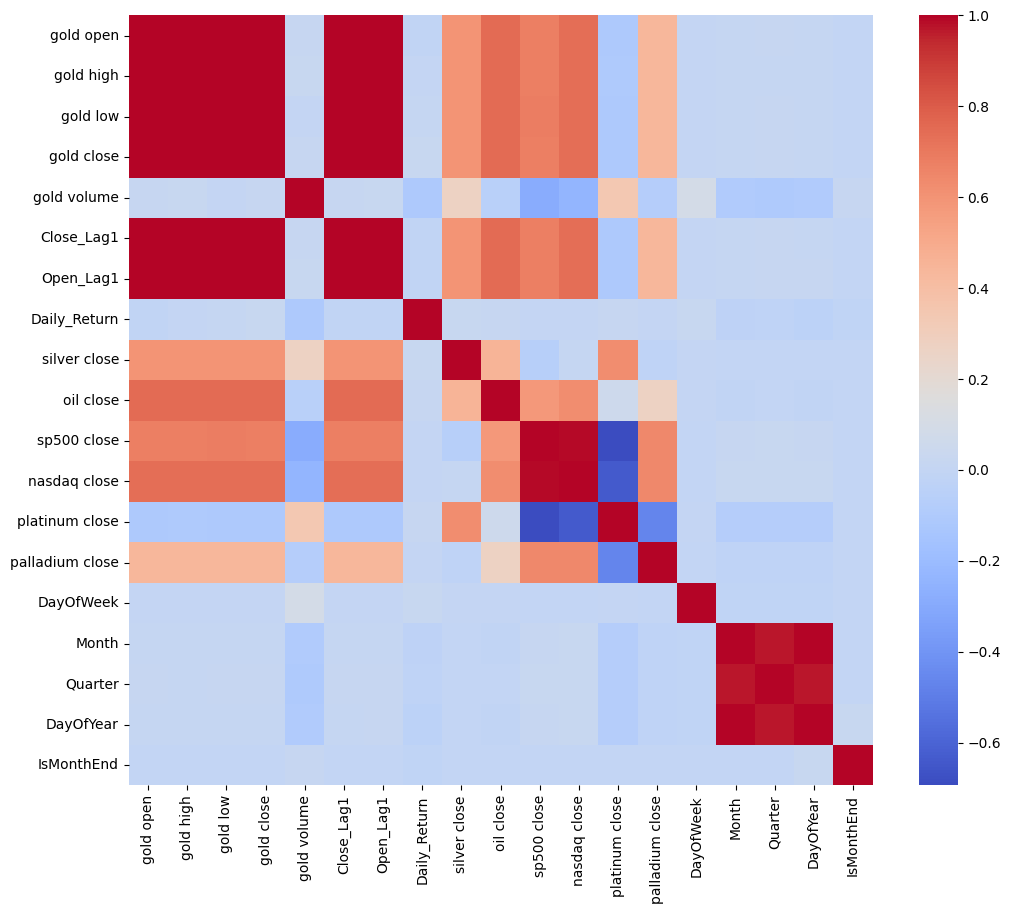

In [42]:
corr = df_clean[features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.show()

In [51]:
split_index = int(len(df_model) * 0.80)

train = df_model.iloc[:split_index].copy()
test = df_model.iloc[split_index:].copy()

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

In [52]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [56]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

In [57]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

In [58]:
from sklearn.model_selection import GridSearchCV

ridge_params = {
    'model__alpha': [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]
}

In [59]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

In [60]:
ridge_search.fit(X_train, y_train)

,estimator,"Pipeline(step...l', Ridge())])"
,param_grid,"{'model__alpha': [0.001, 0.01, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numeric', ...), ('categorical', ...)]"


In [61]:
print("Best Ridge alpha:", ridge_search.best_params_)
print("Best CV score:", ridge_search.best_score_)

Best Ridge alpha: {'model__alpha': 1000}
Best CV score: -9.421091132369303e-05


In [62]:
from xgboost import XGBRegressor

In [63]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        objective='reg:squarederror',
        random_state=42,
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8
    ))
])

In [64]:
numeric_pipeline_xgb = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline_xgb = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_xgb = ColumnTransformer([
    ('numeric', numeric_pipeline_xgb, numeric_features),
    ('categorical', categorical_pipeline_xgb, categorical_features)
])

In [65]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor_xgb),
    ('model', XGBRegressor(
        objective='reg:squarederror',
        random_state=42,
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8
    ))
])

In [66]:
from sklearn.model_selection import cross_validate

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

xgb_cv = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=tscv,
    scoring=scoring,
    n_jobs=-1
)

In [67]:
xgb_results = {
    'Mean MAE': -xgb_cv['test_MAE'].mean(),
    'Mean RMSE': -xgb_cv['test_RMSE'].mean(),
    'Mean R2': xgb_cv['test_R2'].mean()
}

xgb_results

{'Mean MAE': 0.009856173299912997,
 'Mean RMSE': 0.01246547081709164,
 'Mean R2': -0.806655572726401}

In [68]:
ridge_cv = cross_validate(
    ridge_search.best_estimator_,
    X_train,
    y_train,
    cv=tscv,
    scoring=scoring,
    n_jobs=-1
)

ridge_results = {
    'Mean MAE': -ridge_cv['test_MAE'].mean(),
    'Mean RMSE': -ridge_cv['test_RMSE'].mean(),
    'Mean R2': ridge_cv['test_R2'].mean()
}

ridge_results

{'Mean MAE': 0.006907047639272813,
 'Mean RMSE': 0.009547670955795718,
 'Mean R2': -0.03637704522021976}

In [69]:
baseline_predictions = np.zeros(len(y_test))

In [70]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R²:", baseline_r2)

Baseline MAE: 0.006846296113527336
Baseline RMSE: 0.008951759252652155
Baseline R²: -0.0034421733480149985


In [71]:
ridge_search.fit(X_train, y_train)

,estimator,"Pipeline(step...l', Ridge())])"
,param_grid,"{'model__alpha': [0.001, 0.01, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numeric', ...), ('categorical', ...)]"


In [72]:
ridge_pred = ridge_search.predict(X_test)

In [73]:
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

In [74]:
xgb_pipeline.fit(X_train, y_train)

xgb_pred = xgb_pipeline.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)